In [9]:
import csv
import matplotlib.pyplot as plt

In [6]:
X = []
y = []
with open('Iris.csv', 'r') as file:
    reader = csv.reader(file)
    header = next(reader)
    print(header)
    target_feature = 5
    index = 0
    for row in reader:
        data = []
        for i in range(len(row)):
            if i != index and i != target_feature:
                data.append(float(row[i]))
            if i == target_feature:
                y.append(row[i])
        X.append(data)
print(len(X))
print(len(X[0]))
print(y[:5])

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
150
4
['Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa']


In [22]:
# Keep only two classes and two features
X_binary = []
y_binary = []

for i in range(len(X)):
    if y[i] in ['Iris-setosa', 'Iris-versicolor']:
        X_binary.append([X[i][0], X[i][1]])
        if(y[i] == 'Iris-setosa'):
            y_binary.append(-1)
        else:
            y_binary.append(1)

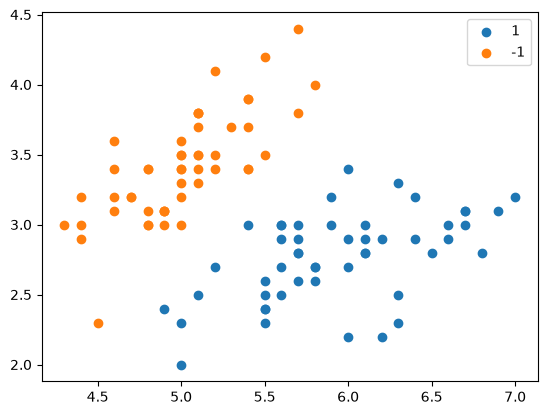

In [23]:
labels = set(y_binary)
for label in labels:
    points = [
        X_binary[i]
        for i in range(len(X_binary))
        if y_binary[i] == label
    ]
    plt.scatter(
        [point[0] for point in points],
        [point[1] for point in points],
        label = label
    )
plt.legend()
plt.show()

In [24]:
def hard_margin_smo(X, y, tol=1e-5,
                    alpha_eps=1e-8,
                    max_passes=30,
                    max_iter=100000):

    n = len(X)

    # Linear kernel: K(i,j) = Xi dot Xj
    K = X @ X.T

    # Start with all alpha values and bias equal to zero
    alpha = np.zeros(n)
    b = 0.0

    # Calculate prediction errors
    def get_errors():
        return (alpha * y) @ K + b - y

    passes = 0
    iterations = 0

    while passes < max_passes and iterations < max_iter:

        changed = 0
        E = get_errors()

        for i in range(n):

            Ei = E[i]

            # Check whether point i violates KKT conditions
            r = y[i] * Ei

            if not (r < -tol or
                    (r > tol and alpha[i] > alpha_eps)):
                continue

            # Try the point with the largest error difference first
            candidates = [j for j in range(n) if j != i]
            candidates.sort(
                key=lambda j: abs(Ei - E[j]),
                reverse=True
            )

            for j in candidates:

                Ej = E[j]

                ai_old = alpha[i]
                aj_old = alpha[j]

                # Find feasible limits for alpha[j]
                if y[i] != y[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = float("inf")
                else:
                    L = 0.0
                    H = ai_old + aj_old

                if H - L < 1e-12:
                    continue

                # Curvature of the dual objective
                eta = K[i, i] + K[j, j] - 2 * K[i, j]

                if eta <= 1e-12:
                    continue

                # Update alpha[j]
                aj_new = aj_old + y[j] * (Ei - Ej) / eta

                # Clip alpha[j] to its feasible range
                aj_new = max(L, min(H, aj_new))

                if abs(aj_new - aj_old) < 1e-8:
                    continue

                # Update alpha[i] to preserve the equality constraint
                ai_new = (
                    ai_old
                    + y[i] * y[j] * (aj_old - aj_new)
                )

                # Calculate two candidate bias values
                b1 = (
                    b - Ei
                    - y[i] * (ai_new - ai_old) * K[i, i]
                    - y[j] * (aj_new - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (ai_new - ai_old) * K[i, j]
                    - y[j] * (aj_new - aj_old) * K[j, j]
                )

                # Select the appropriate bias
                if ai_new > alpha_eps:
                    b = b1
                elif aj_new > alpha_eps:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                # Save updated alpha values
                alpha[i] = max(0.0, ai_new)
                alpha[j] = max(0.0, aj_new)

                changed += 1

                # Recalculate errors after the update
                E = get_errors()

                # Move to the next i
                break

        iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    # Recover w from the learned alpha values
    w = (alpha * y) @ X

    return w, b, alpha, iterations


In [26]:

import numpy as np
X_binary = np.array(X_binary)
y_binary = np.array(y_binary)

w, b, alpha, iterations = hard_margin_smo(X_binary, y_binary)

print("Training iterations:", iterations)
print("Weight vector:", w)
print("Bias:", b)

print("\nHyperplane equation:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + ({b:.4f}) = 0")

margin_width = 2 / np.linalg.norm(w)
print("Total margin width:", margin_width)

Training iterations: 69
Weight vector: [ 6.31576228 -5.26314306]
Bias: -17.31569181248042

Hyperplane equation:
6.3158*x1 + -5.2631*x2 + (-17.3157) = 0
Total margin width: 0.24327097112207183


In [29]:
support_mask = alpha > 1e-5

print("\nSupport vectors:")
for i in range(len(X_binary)):
    if support_mask[i]:
        print(
            f"Point: {X_binary[i]}, "
            f"Class: {int(y_binary[i])}, "
            f"Alpha: {alpha[i]:.6f}"
        )

# Check the hard-margin constraints
functional_margin = y_binary * (X_binary @ w + b)

print("\nMinimum functional margin:",
      np.min(functional_margin))

print("All points satisfy margin >= 1:",
      np.all(functional_margin >= 1 - 1e-4))



Support vectors:
Point: [5.5 3.5], Class: -1, Alpha: 15.545338
Point: [4.5 2.3], Class: -1, Alpha: 18.249551
Point: [4.9 2.4], Class: 1, Alpha: 17.108601
Point: [5.4 3. ], Class: 1, Alpha: 16.686288

Minimum functional margin: 0.9999906047449727
All points satisfy margin >= 1: True


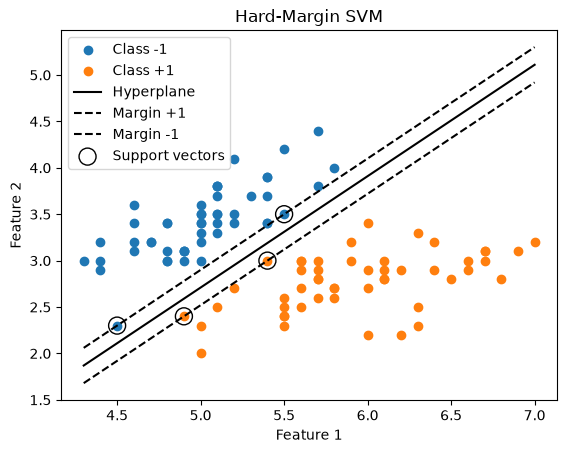

In [36]:
import matplotlib.pyplot as plt

# Plot points by class
plt.scatter(X_binary[y_binary == -1, 0], X_binary[y_binary == -1, 1], label='Class -1')
plt.scatter(X_binary[y_binary == 1, 0], X_binary[y_binary == 1, 1], label='Class +1')

# Plot hyperplane and margins
x1 = np.linspace(X_binary[:, 0].min(), X_binary[:, 0].max(), 100)

plt.plot(x1, -(w[0] * x1 + b) / w[1], 'k-', label='Hyperplane')
plt.plot(x1, -(w[0] * x1 + b - 1) / w[1], 'k--', label='Margin +1')
plt.plot(x1, -(w[0] * x1 + b + 1) / w[1], 'k--', label='Margin -1')

# Highlight support vectors
plt.scatter(X_binary[support_mask, 0], X_binary[support_mask, 1],
            s=150, facecolors='none', edgecolors='black',
            label='Support vectors')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Hard-Margin SVM')
plt.legend()
plt.show()

In [37]:
def soft_margin_smo(X, y, C=1.0, tol=1e-4,
                    eps=1e-7, max_passes=20,
                    max_iter=100000):

    n = len(X)
    K = X @ X.T
    alpha = np.zeros(n)
    b = 0.0
    iterations = 0
    passes = 0

    def errors():
        return (alpha * y) @ K + b - y

    while passes < max_passes and iterations < max_iter:
        changed = 0
        E = errors()

        for i in range(n):
            Ei = E[i]
            ri = y[i] * Ei

            # KKT violation check
            if not (
                (ri < -tol and alpha[i] < C - eps)
                or
                (ri > tol and alpha[i] > eps)
            ):
                continue

            # Try all other points, largest error difference first
            candidates = sorted(
                (j for j in range(n) if j != i),
                key=lambda j: abs(Ei - E[j]),
                reverse=True
            )

            for j in candidates:
                Ej = E[j]
                ai_old, aj_old = alpha[i], alpha[j]

                # Feasible bounds
                if y[i] != y[j]:
                    L = max(0.0, aj_old - ai_old)
                    H = min(C, C + aj_old - ai_old)
                else:
                    L = max(0.0, ai_old + aj_old - C)
                    H = min(C, ai_old + aj_old)

                if H - L < eps:
                    continue

                eta = K[i, i] + K[j, j] - 2 * K[i, j]
                if eta <= eps:
                    continue

                aj_new = aj_old + y[j] * (Ei - Ej) / eta
                aj_new = np.clip(aj_new, L, H)

                if abs(aj_new - aj_old) < eps:
                    continue

                ai_new = ai_old + y[i] * y[j] * (
                    aj_old - aj_new
                )

                b1 = (
                    b - Ei
                    - y[i] * (ai_new - ai_old) * K[i, i]
                    - y[j] * (aj_new - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (ai_new - ai_old) * K[i, j]
                    - y[j] * (aj_new - aj_old) * K[j, j]
                )

                if eps < ai_new < C - eps:
                    b = b1
                elif eps < aj_new < C - eps:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                alpha[i] = ai_new
                alpha[j] = aj_new

                changed += 1
                E = errors()
                break

        iterations += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    w = (alpha * y) @ X
    return w, b, alpha, iterations


In [39]:
C = 1.0
w, b, alpha, iterations = soft_margin_smo(X_binary, y_binary, C=C)

# Decision function
scores = X_binary @ w + b
predictions = np.where(scores >= 0, 1.0, -1.0)

# Functional margin for each point
functional_margin = y_binary * scores

# Support vectors: alpha > 0
support_mask = alpha > 1e-5

# Points inside or on the margin
margin_mask = functional_margin <= 1 + 1e-4

# Incorrectly classified points
misclassified_mask = functional_margin < -1e-4

print("Iterations:", iterations)
print("C:", C)
print("\nWeight vector:", w)
print("Bias:", b)

print("\nLearned hyperplane:")
print(f"{w[0]:.4f}*x1 + {w[1]:.4f}*x2 + ({b:.4f}) = 0")

print("\nMargin width:", 2 / np.linalg.norm(w))
print("Number of support vectors:", np.sum(support_mask))
print("Number inside/on margin:", np.sum(margin_mask))
print("Number misclassified:", np.sum(misclassified_mask))

print("\nSupport vector details:")
for i in range(len(X_binary)):
    if support_mask[i]:
        print(
            f"Point={X_binary[i]}, label={int(y_binary[i])}, "
            f"alpha={alpha[i]:.4f}, "
            f"y*f(x)={functional_margin[i]:.4f}"
        )

print("\nMisclassified points:")
for i in np.where(misclassified_mask)[0]:
    print(
        f"Point={X_binary[i]}, true={int(y_binary[i])}, "
        f"predicted={int(predictions[i])}"
    )

print("\nEquality constraint sum(alpha*y):",
      np.sum(alpha * y_binary))

print("All alpha values within [0, C]:",
      np.all(alpha >= -1e-6) and np.all(alpha <= C + 1e-6))


print("\nKKT diagnostic:")

for i in range(len(X_binary)):
    print(
        f"i={i:2d}, point={X_binary[i]}, "
        f"y*f(x)={functional_margin[i]:7.3f}, "
        f"alpha={alpha[i]:7.4f}"
    )



Iterations: 30
C: 1.0

Weight vector: [ 2.2272 -2.2496]
Bias: -4.94176000000041

Learned hyperplane:
2.2272*x1 + -2.2496*x2 + (-4.9418) = 0

Margin width: 0.6317887150442498
Number of support vectors: 17
Number inside/on margin: 17
Number misclassified: 0

Support vector details:
Point=[4.9 3. ], label=-1, alpha=1.0000, y*f(x)=0.7773
Point=[4.8 3. ], label=-1, alpha=0.6237, y*f(x)=1.0000
Point=[5.7 3.8], label=-1, alpha=1.0000, y*f(x)=0.7952
Point=[5.4 3.4], label=-1, alpha=1.0000, y*f(x)=0.5635
Point=[5. 3.], label=-1, alpha=1.0000, y*f(x)=0.5546
Point=[5.4 3.4], label=-1, alpha=1.0000, y*f(x)=0.5635
Point=[5.5 3.5], label=-1, alpha=1.0000, y*f(x)=0.5658
Point=[4.5 2.3], label=-1, alpha=1.0000, y*f(x)=0.0934
Point=[4.8 3. ], label=-1, alpha=0.1283, y*f(x)=1.0000
Point=[4.9 2.4], label=1, alpha=1.0000, y*f(x)=0.5725
Point=[5.2 2.7], label=1, alpha=1.0000, y*f(x)=0.5658
Point=[5.6 3. ], label=1, alpha=1.0000, y*f(x)=0.7818
Point=[5.9 3.2], label=1, alpha=0.7520, y*f(x)=1.0000
Point=[5.4

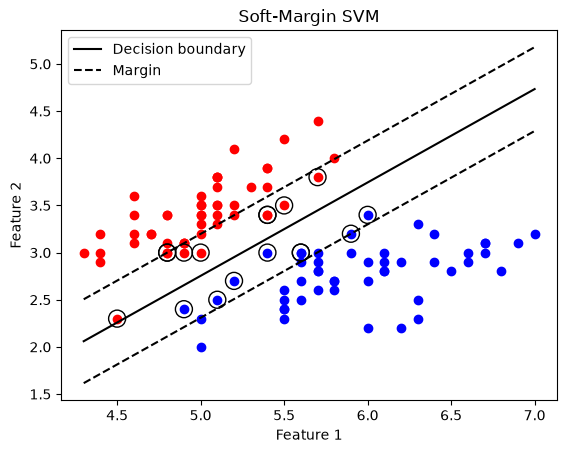

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# Plot data points
for i in range(len(X_binary)):
    if y_binary[i] == -1:
        plt.scatter(X_binary[i][0], X_binary[i][1], color='red')
    else:
        plt.scatter(X_binary[i][0], X_binary[i][1], color='blue')

# Highlight support vectors
plt.scatter(X_binary[support_mask, 0],
            X_binary[support_mask, 1],
            s=150, facecolors='none', edgecolors='black')

# Decision boundary and margins
x1 = np.linspace(X_binary[:, 0].min(), X_binary[:, 0].max(), 100)

plt.plot(x1, -(w[0] * x1 + b) / w[1], 'k-', label='Decision boundary')
plt.plot(x1, -(w[0] * x1 + b - 1) / w[1], 'k--', label='Margin')
plt.plot(x1, -(w[0] * x1 + b + 1) / w[1], 'k--')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Soft-Margin SVM')
plt.legend()
plt.show()